# Fashion-MNIST Classification — Transfer Learning (MobileNetV2)

### 1. Data Preparation

In [8]:
import numpy as np, matplotlib.pyplot as plt, seaborn as sns, tensorflow as tf
from tensorflow import keras
from sklearn.metrics import confusion_matrix, classification_report, precision_recall_fscore_support

(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
x_train, y_train = x_train[:8000], y_train[:8000]   # subset = fast
names = ['T-shirt','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Boot']
IMG = 64

def prep(x, y):
    x = tf.image.grayscale_to_rgb(tf.expand_dims(x, -1))
    x = tf.image.resize(x, (IMG, IMG))
    x = keras.applications.mobilenet_v2.preprocess_input(tf.cast(x, tf.float32))
    return x, y

def ds(x, y): return tf.data.Dataset.from_tensor_slices((x, y)).map(prep).batch(256).prefetch(1)
train_ds, test_ds = ds(x_train, y_train), ds(x_test, y_test)
print("Ready:", x_train.shape, x_test.shape)

Ready: (8000, 28, 28) (10000, 28, 28)


### 2. Model Implementation (Transfer Learning)

In [9]:
base = keras.applications.MobileNetV2(input_shape=(IMG,IMG,3), include_top=False, weights='imagenet')
base.trainable = False
model = keras.Sequential([base, keras.layers.GlobalAveragePooling2D(),
                           keras.layers.Dropout(0.3), keras.layers.Dense(10, activation='softmax')])
model.compile('adam', 'sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

/tmp/ipykernel_4724/3497238414.py:1: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = keras.applications.MobileNetV2(input_shape=(IMG,IMG,3), include_top=False, weights='imagenet')


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 2, 2, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### 3. Model Training

In [10]:
history = model.fit(train_ds, validation_data=test_ds, epochs=30)

Epoch 1/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 71s 2s/step - accuracy: 0.4874 - loss: 1.5846 - val_accuracy: 0.7323 - val_loss: 0.8197
Epoch 2/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 63s 2s/step - accuracy: 0.7345 - loss: 0.8010 - val_accuracy: 0.7780 - val_loss: 0.6693
Epoch 3/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 63s 2s/step - accuracy: 0.7724 - loss: 0.6675 - val_accuracy: 0.7972 - val_loss: 0.6038
Epoch 4/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 62s 2s/step - accuracy: 0.8002 - loss: 0.5911 - val_accuracy: 0.8077 - val_loss: 0.5633
Epoch 5/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 63s 2s/step - accuracy: 0.8129 - loss: 0.5408 - val_accuracy: 0.8151 - val_loss: 0.5388
Epoch 6/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 83s 2s/step - accuracy: 0.8292 - loss: 0.5023 - val_accuracy: 0.8216 - val_loss: 0.5217
Epoch 7/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 64s 2s/step - accuracy: 0.8349 - loss: 0.4698 - val_accuracy: 0.8243 - val_loss: 0.5092
Epoch 8/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 81s 2s/step - accuracy: 0.8471 - loss: 0.4491 - val_accuracy: 0.8250 - val_loss:

### 4. Performance Evaluation

In [11]:
y_pred = np.argmax(model.predict(test_ds), axis=1)
p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='weighted')
acc = model.evaluate(test_ds)[1]
print(f"Accuracy: {acc:.4f}  Precision: {p:.4f}  Recall: {r:.4f}  F1: {f1:.4f}")
print(classification_report(y_test, y_pred, target_names=names))

40/40 ━━━━━━━━━━━━━━━━━━━━ 33s 787ms/step
40/40 ━━━━━━━━━━━━━━━━━━━━ 30s 731ms/step - accuracy: 0.8343 - loss: 0.4761
Accuracy: 0.8343  Precision: 0.8370  Recall: 0.8343  F1: 0.8349
              precision    recall  f1-score   support

     T-shirt       0.83      0.71      0.77      1000
     Trouser       0.97      0.95      0.96      1000
    Pullover       0.77      0.79      0.78      1000
       Dress       0.77      0.82      0.79      1000
        Coat       0.74      0.74      0.74      1000
      Sandal       0.93      0.92      0.93      1000
       Shirt       0.59      0.63      0.61      1000
     Sneaker       0.89      0.92      0.90      1000
         Bag       0.95      0.94      0.94      1000
        Boot       0.94      0.94      0.94      1000

    accuracy                           0.83     10000
   macro avg       0.84      0.83      0.83     10000
weighted avg       0.84      0.83      0.83     10000



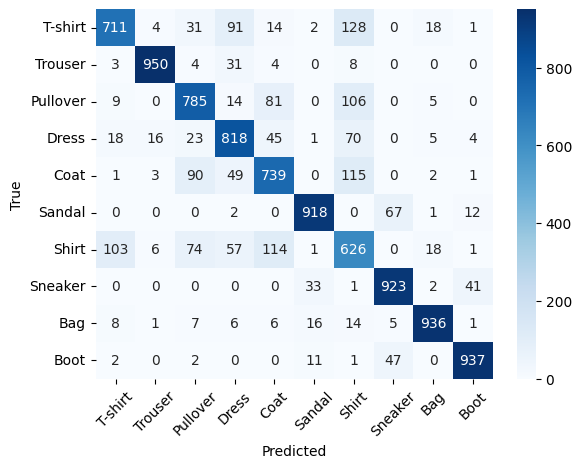

In [12]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', xticklabels=names, yticklabels=names, cmap='Blues')
plt.xticks(rotation=45); plt.xlabel('Predicted'); plt.ylabel('True'); plt.show()

### 5. Result Analysis

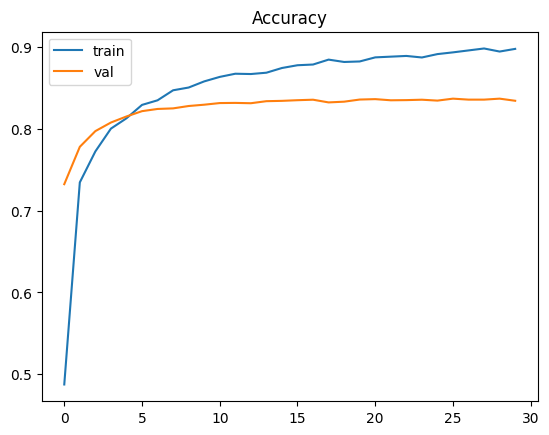

In [13]:
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.legend(); plt.title('Accuracy'); plt.show()

In [14]:
for n, a in sorted(zip(names, cm.diagonal()/cm.sum(1)), key=lambda t: t[1]):
    print(f"{n:10s}: {a:.3f}")

Shirt     : 0.626
T-shirt   : 0.711
Coat      : 0.739
Pullover  : 0.785
Dress     : 0.818
Sandal    : 0.918
Sneaker   : 0.923
Bag       : 0.936
Boot      : 0.937
Trouser   : 0.950
